Ноутбук служит основой для изучения, однако многое нужно будет поискать и почитать самостоятельно. В некоторых заданиях (да и вообще по теме) это дз будет опираться на материал пары.
***

В этом домашнем задании мы (вы) поговорим о, как не странно, **визуализации**. Но говорить о ней надо на каком-то материале. В этот раз немного отдохнем от данных и сами их посоздаем, по моделируем (ну почти).

Я уверена, что вы уже так или иначе владеете кодовыми библиотеками `matplotlib` и `seaborn`, поэтому просто напомню базовый чек-лист из прошлого задания про построение графиков.

- [x] должно быть **понятно**, что изображено на графике;  
- [x] должны присутствовать **названия осей** (за исключением, когда это очевидно);  
- [x] если на графике присутствуют разные данные, то должна быть **легенда**.

В этом дз мы скорее изучим какие-то неочевидные и/или прикольные интересности, чем пройдемся по базовым вещам.  
Для знакомства с базой вот вам [мой любимый простой гайд](https://skillbox.ru/media/code/biblioteka-matplotlib-dlya-postroeniya-grafikov/),
[документация](https://matplotlib.org/3.6.2/users/index.html)
и еще немного материала: [доступен просто так](https://devpractice.ru/matplotlib-lesson-1-quick-start-guide/),
[доступен не просто так](https://pythonworld.ru/novosti-mira-python/scientific-graphics-in-python.html).

# Задание 1: Дискретная непрерывность (2 pt)

Вы знаете, что при $n \rightarrow \infty$ **геометрическое распределение** стремится к **экспоненциальному**
$$\frac{1}{n} Geom\Bigg(\frac{\lambda}{n}\Bigg) \rightarrow Exp(\lambda).$$
Давайте графически это подтвердим!

Для этого нам понадобится:
- [ ] умение [генерировать](####Генерация) случайные величины;
- [ ] умение получать [теоретическую](####Теоретическое-в-коде) плотность;
- [ ] умение [строить](####Построение-графиков) гистограммы;
- [ ] умение [сглаживать](####Сглаживание) данные;
- [ ] умение строить [несколько](####Несколько-графиков) графиков в одной фигуре

*Много теории только тут, дальше столько не будет. Не пропускайте ее, пожалуйста, ну или хотя бы обращайте внимание на выделенное*

#### Генерация

В Python существует **два основных подхода к генерации случайных величин** из различных распределений:  
* `numpy.random`
* `scipy.stats`

В первом случае генерация происходит "на прямую", а во втором как получение выборки конкретной случайной велечины (как метод объекта). Работает `scipy.stats` чуть медленнее, однако это некритично для небольших объемов и точечных вызовов.

Генерация в `numpy.random` происходит через вызов конкретных методов для каждого распределения: `np.random.uniform(a, b, size)`, `np.random.normal(loc, scale, size)`, `np.random.exponential(scale, size)` и так далее.

<div class="alert alert-danger">
<b>ВАЖНО:</b> в экспоненциальном распределении scale = 1/$\lambda$, а не $\lambda$.
</div>

Подробнее как всегда читайте в [документации](https://numpy.org/doc/2.1/reference/random/generator.html), но в этом задании лучше использовать `scipy.stats`.

При этом в обоих случаях не забывайте **фиксировать** `np.random.seed(42)` для **воспроизводимости** результатов!
***

Логика работы со случайными величинами в `scipy.stats` всегда примерно одинаковая:

```python
from scipy import stats

# Создание случайной величины как объекта
xi = stats.norm(loc=0, scale=1)

# Генерация выборки
samples = xi.rvs(size=1000)

pdf_values = xi.pdf(x)      # Плотность вероятности
cdf_values = xi.cdf(x)      # Функция распределения
ppf_values = xi.ppf(q)      # Квантильная функция (обратная CDF)
mean = xi.mean()            # Математическое ожидание
var = xi.var()              # Дисперсия
...
```

При этом в этом модуле реализовано оооооочень много разных распределений!  
| Распределение | Класс | Параметры |
| :------------ | :---- | :-------- |
| **Равномерное** $U(a,b)$ | `stats.uniform` | `loc=a`, `scale=b-a` |
| **Нормальное** $N(\mu,\sigma^2)$ | `stats.norm` | `loc`=$\mu$, `scale`=$\sigma$ |
| **Биномиальное** $Bin(n,p)$ | `stats.binom` | `n`, `p` |
| **Экспоненциальное** $Exp(\lambda)$ | `stats.expon` | `scale`=1/$\lambda$ |
| **Пуассоновское** $Pois(\lambda)$ | `stats.poisson` | `mu`=$\lambda$ |
| **Геометрическое** $Geom(p)$ | `stats.geom` | `p` |
| **Гамма** $Gamma(\alpha,\beta)$ | `stats.gamma` | `a`=$\alpha$, `scale`=1/$\beta$` |
| **Бета** $Beta(\alpha,\beta)$ | `stats.beta` | `a`=$\alpha$, `b`=$\beta$` |
| **Отрицательное биномиальное** $NegBin(r,p)$ | `stats.nbinom` | `n=r`, `p` |
| **Бета-биномиальное** | `stats.betabinom` | `n`, `a`=$\alpha$, `b`=$\beta$` |
| **Стьюдента** $T(d)$ | `stats.t` | `loc=a`, `df=d` |

Как всегда подробнее читайте в [документации](https://docs.scipy.org/doc/scipy/reference/stats.html).

#### Теоретическое в коде


Как было показано ранее из объектов класса распределения можно получать теоретические вещи:
- функцию распределения,
- плотность,
- ожидание,
- дисперсию и так далее
```python
xi = stats.norm(loc=0, scale=1)
cdf_values = xi.cdf(x)
```

Но для дискретных распределений нужно использовать вероятностную массовую функцию (**PMF**), а не плотность (**PDF**). А также их можно получать не от объекта класса, а **через методы сразу**:
```python
binom_pmf = stats.binom.pmf(k, n=100, p=0.05)
```
Для визуализации такого можно использовать `plt.stem()`.

#### Построение графиков

Для построения графиков, очевидно, понадобится `matplotlib.pyplot` или `seaborn`.

Если мы работаем с распределениями, то нам точно понадобятся следующие графики:
| Тип графика | Когда использовать | Пример |
| :---------- | :----------------- | :----- |
| **Гистограмма** (`plt.hist`) | Для отображения эмпирических данных | Приближенная визуализация распределения |
| **Столбчатая диаграмма** (`plt.bar`) | Для дискретных распределений (точное совпадение с целыми значениями) | Визуализация `Pois(λ)` или `Bin(n, p)` без искажения дискретной природы |
| **Линейный график плотности** (`plt.plot`) | Для непрерывных распределений или сглаженных оценок | Наложение теоретической кривой на гистограмму |
| **Точечный график с линиями** (`plt.plot(..., 'o-')`) | Для дискретных распределений при сравнении с теорией | Отображение `pmf` дискретного распределения поверх гистограммы |

**Параметры**

Для лучшей и более понятной визуализации важно уметь работать со следующими параметрами:
| Параметр | За что отвечает | Когда использовать | Пример |
|----------|----------------|-------------------|--------|
| `density=True` | Нормализует гистограмму так, чтобы **площадь = 1** | **Всегда** при сравнении с теоретической плотностью/`pmf` | `plt.hist(data, bins=30, density=True)` |
| `bins` | Количество или границы интервалов гистограммы | Для дискретных распределений: `bins=range(min, max+1)` | `plt.hist(data, bins=range(0, 20))` |
| `alpha` | Прозрачность элемента (0.0–1.0) | При наложении нескольких графиков для видимости перекрытия | `plt.hist(..., alpha=0.6)` |
| `color` / `edgecolor` | Цвет заливки и границ | Для визуального разделения компонентов смеси | `color='skyblue', edgecolor='black'` |
| `label` + `plt.legend()` | Подпись элемента и отображение легенды | При сравнении нескольких распределений на одном графике | `label='Эмпирические данные'` |
| `ax.grid(True, alpha=0.3)` | Добавление сетки | **Всегда** — улучшает читаемость и оценку значений | `ax.grid(True, linestyle='--', alpha=0.3)` |
| `ax.set_xlabel()` / `ax.set_ylabel()` | Подписи осей | **Всегда** — без подписей график непонятен | `ax.set_xlabel('Время между покупками (часы)')` |
| `ax.set_title()` | Заголовок графика | Для краткого описания содержания | `ax.set_title('Сходимость Bin(...) -> Pois(...)')` |
| `ax.annotate()` | Текстовая аннотация со стрелкой | Для выделения ключевых точек (максимумы, пороги) | См. пример ниже |
| `plt.tight_layout()` | Автоматическая настройка отступов | **Перед сохранением** — предотвращает обрезку элементов | `plt.tight_layout()` |
| `dpi` в `savefig()` | Разрешение изображения | Для отчётов: `dpi=150`, для публикаций: `dpi=300` | `plt.savefig('graph.png', dpi=150)` |



Для сравнения данных нам понадобится именно гистограммы (нормированные диаграммы), этого можно добиться при помощи параметра `density=True`: она автоматически нормируется так, чтобы *площадь под диаграммой равнялась 1*.

Подробнее в [документации](https://matplotlib.org/stable/api/pyplot_summary.html).

#### Сглаживание

Когда мы работаем с гистограммой, мы работаем с кусочным объектом, который **зависит от разбиения** (бинов). Поэтому иногда полезно видеть **сглаженную** кривую, которая лучше показывает форму распределения.

Для этой цели можно использовать **ядерное сглаживание** `gaussian_kd`:
* Ядро сглаживания строит гладкую кривую через данные
* Параметр `bw_method` регулирует "гладкость" (по умолчанию — оптимальный)
* Для малых выборок используйте `kde = gaussian_kde(data, bw_method=0.5)`
```python
kde = gaussian_kde(data)
x = np.linspace(min(data), max(data), 1000)
plt.plot(x, kde(x))
```

**Как выбрать** параметр `bw_method`?

```python
# Слишком гладко (теряем детали)
kde1 = gaussian_kde(samples, bw_method=2.0)

# Оптимально (по умолчанию)
kde2 = gaussian_kde(samples, bw_method='scott')  # или 'silverman'

# Слишком "рвано" (шум вместо сигнала)
kde3 = gaussian_kde(samples, bw_method=0.1)
```

<div class="alert alert-danger">
<b>ВАЖНО:</b> Сглаживание может ввести в заблуждение — создать иллюзию непрерывности.
</div>

Подробнее угадайте где? В [документации](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.gaussian_kde.html)!

#### Несколько графиков

Когда нужно сравнить распределения при разных параметрах или показать эволюцию процесса, **одного графика недостаточно**. В этом случае используем **сетку графиков (subplots)**.

**Базовый синтаксис**: `plt.subplots()`

```python
import matplotlib.pyplot as plt

# Создание сетки 2x3 (2 строки, 3 столбца)
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 8))
# axes — это двумерный массив объектов осей

# Доступ к отдельным графикам
ax_top_left = axes[0, 0]    # верхний левый
ax_bottom_right = axes[1, 2]  # нижний правый

# Если нужен одномерный массив (удобнее для циклов)
axes_flat = axes.flatten()  # превращает (2,3) → (6,)
```

**Ключевые параметры**:

| Параметр | За что отвечает | Пример |
| :------- | :-------------- | :----- |
| `nrows`, `ncols` | Количество строк и столбцов |  `plt.subplots(2, 3)` -> сетка 2x3 |
| `figsize=(w, h)` | Размер всей фигуры в дюймах | `figsize=(14, 6)` — широкая фигура для горизонтального сравнения |
| `sharex=True/False` | Общая ось X для всех графиков | При сравнении распределений с одинаковым диапазоном значений |
| `sharey=True/False` | Общая ось Y для всех графиков | При сравнении плотностей или диаграмм с одинаковым масштабом |
| `squeeze=True` *(по умолчанию)* | Упрощает форму массива `axes` | При `nrows=1`, `ncols=1` возвращает один объект `ax`, а не массив 1x1 |
| `gridspec_kw` | Тонкая настройка размеров ячеек | `gridspec_kw={'width_ratios': [2, 1]}` — первый график в 2 раза шире второго |

Ну и подробнее в любимой [документации](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html).

***
## Задание (2 pt)

Изучите приближение геометрического распределения к экспоненциальному через визуализацию.

**Постройте сетку 2×2 графиков для разных значений $n$ (20, 50, 100, 1000) при фиксированном значении $\lambda=2$**  
**На каждом графике** отобразите:
- гистограмму выборки из $\frac{1}{n} Geom\big(\frac{\lambda}{n}\big)$,
- теоретическую плотность соответствующего экспоненциального,
- сглаженную плотность из данных,
- легенду с нужными значениями.

Для этого используйте нужные виды графиков, цветовую дифференциацию, правильные подписи и вообще _**всю красоту**_.

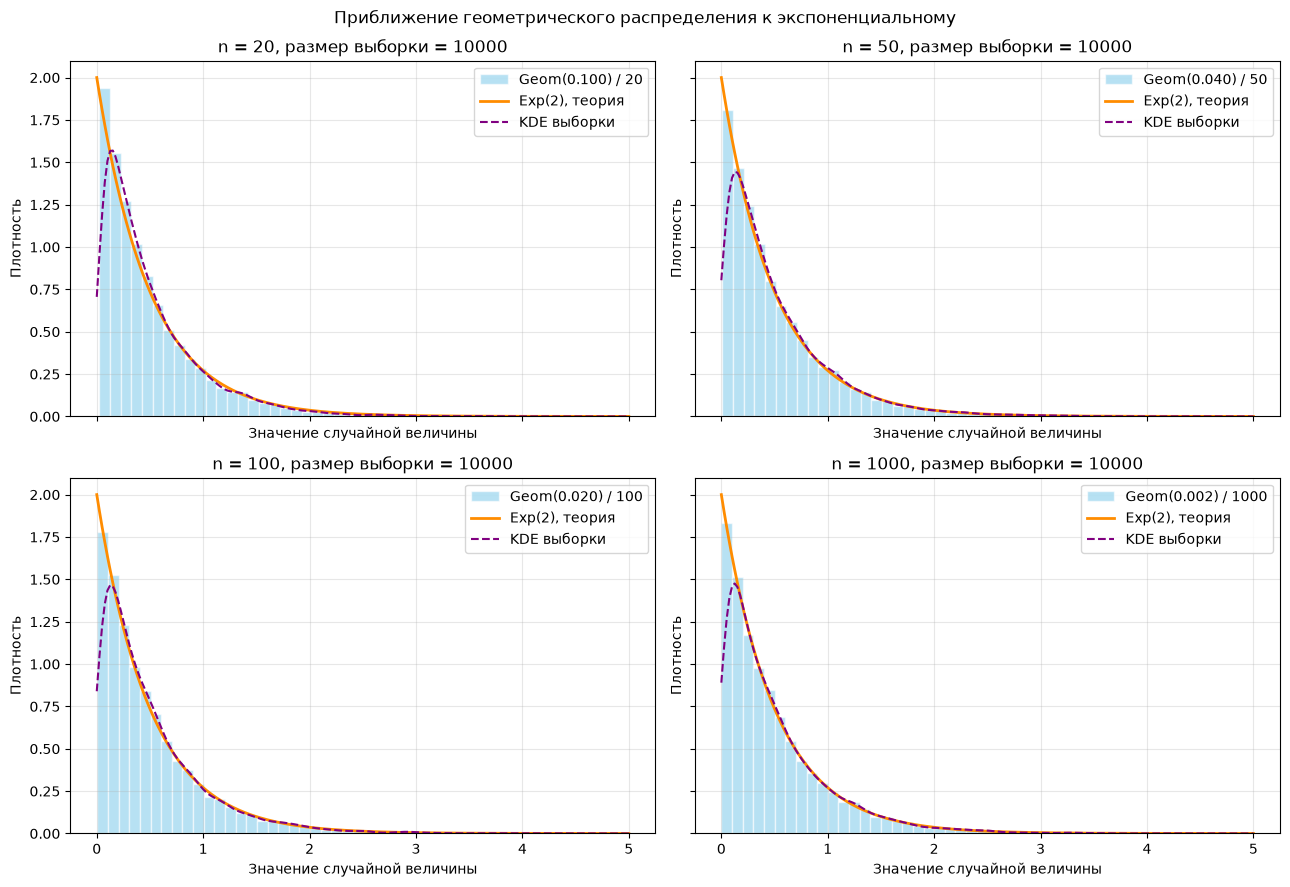

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import gaussian_kde

np.random.seed(42)
lambda_param = 2.0
n_values = [20, 50, 100, 1000]
n_samples = 10000  # размер выборки для каждого n

# Создайте сетку 2x2
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True, sharey=True)
axes = axes.flatten()

for idx, n in enumerate(n_values):
    ax = axes[idx]
    samples = stats.geom.rvs(p=lambda_param / n, size=n_samples) / n
    step = max(1, round(0.1 * n)) / n
    bins = np.arange(0.5 / n, samples.max() + step, step)

    ax.hist(samples, bins=bins, density=True, alpha=0.6, color='skyblue',
            edgecolor='white', label=f'Geom({lambda_param / n:.3f}) / {n}')

    x_vals = np.linspace(0, 5, 200)
    exp_pdf = stats.expon.pdf(x_vals, scale=1 / lambda_param)
    ax.plot(x_vals, exp_pdf, color='darkorange', linewidth=2, label='Exp(2), теория')

    kde = gaussian_kde(samples)
    ax.plot(x_vals, kde(x_vals), color='purple', linestyle='--', label='KDE выборки')

    ax.set_xlabel('Значение случайной величины')
    ax.set_ylabel('Плотность')
    ax.set_title(f'n = {n}, размер выборки = {n_samples}')
    ax.legend()
    ax.grid(alpha=0.3)

fig.suptitle('Приближение геометрического распределения к экспоненциальному')
plt.tight_layout()
# plt.savefig('task1_geometric_exponential.png', dpi=150, bbox_inches='tight') МОЖНО СОХРАНИТЬ, А НЕ ПРОСТО ВЫВЕСТИ
plt.show()

# Задание 2: Не детские смеси (3 pt)

В этом задании мы повизуализируем смеси. Все нужые **ссылки и прочее уже были даны ранее**, добавлю только несколько фич:

| Фича | Метод | Зачем использовать |
| :--- | :---- | :----------------- |
| **Аннотации со стрелками** | `ax.annotate()` | Выделение ключевых точек графика с визуальной связью между текстом и объектом |
| **Текстовые блоки с фоном** | `ax.text()` + `bbox` | Добавление поясняющего текста с выделением фона для читаемости |
| **Вертикальные/горизонтальные линии** | `ax.axvline()`, `ax.axhline()` | Выделение порогов, средних значений, квантилей |
| **Заливка областей** | `ax.fill_between()`, `axvspan()` | Визуализация доверительных интервалов, выделение зон интереса |
| **Настройка шрифтов** | `fontdict`, `fontsize` | Единый стиль оформления текстовых элементов |
| **Стили линий и маркеров** | `linestyle`, `marker` | Различение нескольких кривых без цвета |

У всего этого куча интересных параметров, за ними идите в [ДО](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.annotate.html)
[КУ](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.text.html)
[МЕН](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.axvline.html)
[ТА](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.fill_between.html)
[ЦИ](https://matplotlib.org/stable/gallery/text_labels_and_annotations/accented_text.html)
[Ю](https://matplotlib.org/stable/gallery/text_labels_and_annotations/annotation_basic.html)!

## «Теоретическое» задание (1,5 pt)

Смоделируйте **загрязнённое нормальное распределение**, которое можно встретить, например, в ситуации, когда есть основная группа пользователей и малая часть "активных"

$$(1 - \varepsilon) \cdot N(\mu, \sigma^2) + \varepsilon \cdot N(\mu, \alpha\sigma^2).$$

Ваша **необходимо**:
1. Сгенерировать **выборку** из загрязненного нормального распределения с параметрами:
   - $\mu = 0$, $\sigma =  1$
   - $\varepsilon = 0.15$ *(вот тут появляется Бернулли)*
   - $\alpha = 4$
2. Построить **один график** со следующими элементами:
   - Гистограмма эмпирических данных (серый цвет, `alpha=0.6`)
   - Теоретическая плотность основного компонента (синяя линия, `alpha=0.7`)
   - Теоретическая плотность загрязняющего компонента (красная линия, `alpha=0.7`)
   - Полная теоретическая плотность смеси (чёрная пунктирная линия, толщина 2.5)
   - Сравнение с "чистым" нормальным распределением (фиолетовая штрихпунктирная линия) — *чтобы показать, как загрязнение искажает форму*
   - Аннотация со стрелкой, указывающая на "тяжёлые хвосты" от загрязняющего компонента
   - Текстовый блок с параметрами смеси и интерпретацией (используйте `bbox`)

В этом задании для генерации используем `numpy.random`.

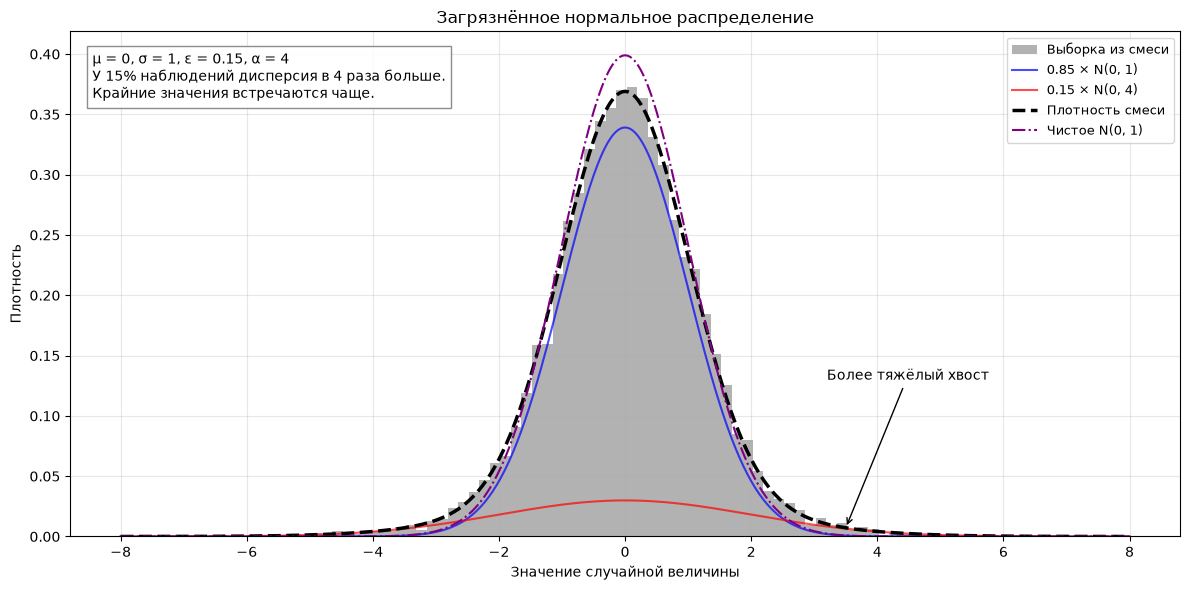

In [2]:
np.random.seed(42)

mu = 0
sigma = 1
epsilon = 0.15
alpha = 4
n_samples = 10000

# Генерация смеси
is_contaminated = np.random.binomial(1, epsilon, n_samples)
main_component = np.random.normal(mu, sigma, n_samples)
contaminated_component = np.random.normal(mu, np.sqrt(alpha) * sigma, n_samples)
mixture = np.where(is_contaminated == 1, contaminated_component, main_component)

# Создание графика
fig, ax = plt.subplots(figsize=(12, 6))

# Гистограмма
ax.hist(mixture, bins=70, density=True, color='gray', alpha=0.6, label='Выборка из смеси')

# Теоретические компоненты
x_vals = np.linspace(-8, 8, 500)
main_pdf = (1 - epsilon) * stats.norm.pdf(x_vals, loc=mu, scale=sigma)
ax.plot(x_vals, main_pdf, color='blue', alpha=0.7, label='0.85 × N(0, 1)')

contaminated_pdf = epsilon * stats.norm.pdf(x_vals, loc=mu, scale=np.sqrt(alpha) * sigma)
ax.plot(x_vals, contaminated_pdf, color='red', alpha=0.7, label='0.15 × N(0, 4)')

mixture_pdf = main_pdf + contaminated_pdf
ax.plot(x_vals, mixture_pdf, color='black', linestyle='--', linewidth=2.5, label='Плотность смеси')

# Чистое нормальное для сравнения
pure_normal_pdf = stats.norm.pdf(x_vals, loc=mu, scale=sigma)
ax.plot(x_vals, pure_normal_pdf, color='purple', linestyle='-.', label='Чистое N(0, 1)')

# Аннотация на тяжёлые хвосты
ax.annotate('Более тяжёлый хвост', xy=(3.5, np.interp(3.5, x_vals, mixture_pdf)),
            xytext=(3.2, 0.13), arrowprops={'arrowstyle': '->', 'color': 'black'})

# Текстовый блок с интерпретацией
interpretation_text = ('μ = 0, σ = 1, ε = 0.15, α = 4\n'
                       'У 15% наблюдений дисперсия в 4 раза больше.\n'
                       'Крайние значения встречаются чаще.')
ax.text(0.02, 0.96, interpretation_text, transform=ax.transAxes, va='top', fontsize=10,
        bbox={'facecolor': 'white', 'alpha': 0.9, 'edgecolor': 'gray'})

# Оформление
ax.set_xlabel('Значение случайной величины')
ax.set_ylabel('Плотность')
ax.set_title('Загрязнённое нормальное распределение')
ax.legend(loc='upper right', fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()
# plt.savefig('task2_contaminated_normal.png', dpi=150, bbox_inches='tight')
plt.show()

## Практическое задание (1,5 pt)

В этом задании мы все же поработаем с данными, но с теми, с которыми вы уже знакомы! Будем снова говорить про пингвинчиков)

Вам **необходимо**:
1. Загрузить датасет и удалить строки с пропущенными значениями в столбце `bill_length_mm`
2. Построить **два графика** на **одной фигуре** (сетка 1×2):
   - Левый график: **Общая гистограмма** длины клюва всех пингвинов + наложенные плотности для каждого вида (разные цвета, `alpha=0.6`)
   - Правый график: **Три отдельные гистограммы** по видам (на одном графике для сравнения) с **теоретическими нормальными кривыми**
3. На левом графике добавьте:
   - **Аннотацию со стрелкой на бимодальность** (место между пиками)
   - **Текстовый блок с интерпретацией**: почему общее распределение выглядит как смесь?
   - **Вертикальные линии**, показывающие средние значения для каждого вида
4. На правом графике добавьте:
   - **Легенду** с указанием вида и количества особей
   - **Подпись с выводом**: *какой вид имеет наибольшую вариабельность длины клюва?*

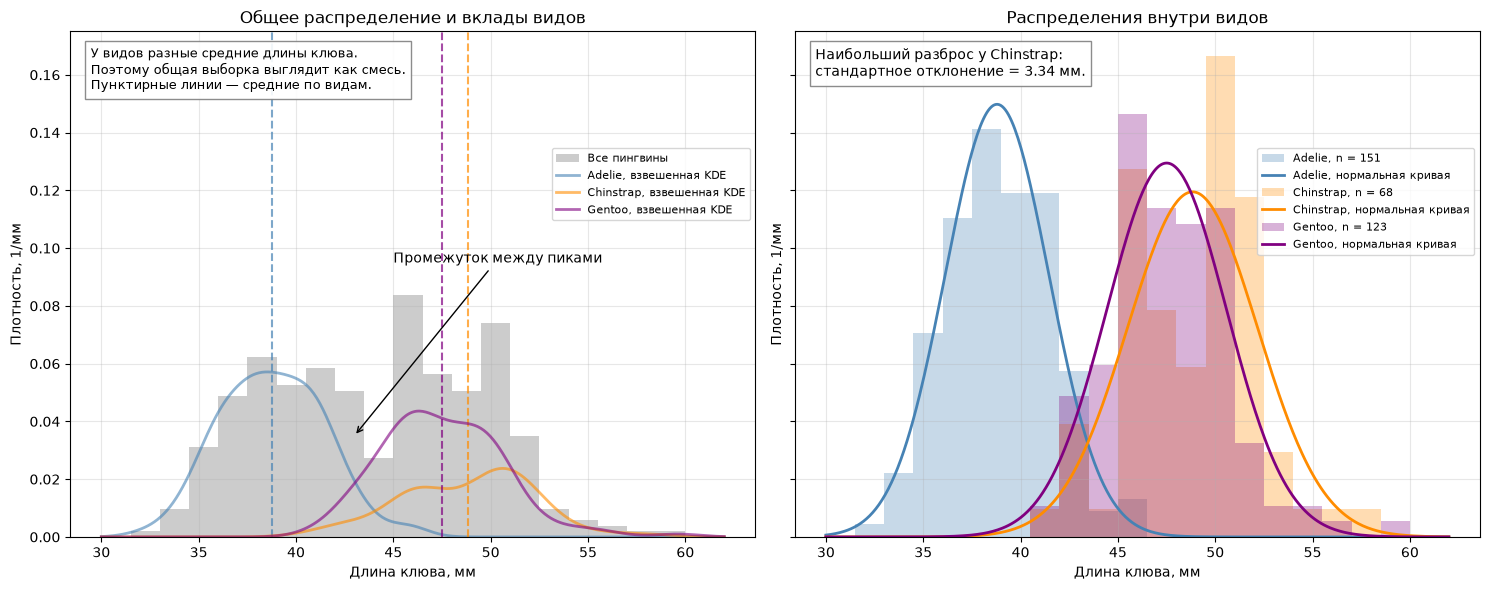

In [3]:
import seaborn as sns

penguins = sns.load_dataset('penguins', data_home='.')
penguins_clean = penguins.dropna(subset=['bill_length_mm'])

adelie = penguins_clean.loc[penguins_clean['species'] == 'Adelie', 'bill_length_mm']
chinstrap = penguins_clean.loc[penguins_clean['species'] == 'Chinstrap', 'bill_length_mm']
gentoo = penguins_clean.loc[penguins_clean['species'] == 'Gentoo', 'bill_length_mm']
all_penguins = penguins_clean['bill_length_mm']

# Вычисление параметров
mu_adelie, std_adelie = adelie.mean(), adelie.std()
mu_chinstrap, std_chinstrap = chinstrap.mean(), chinstrap.std()
mu_gentoo, std_gentoo = gentoo.mean(), gentoo.std()

# Создание графиков
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
x_vals = np.linspace(30, 62, 400)
bins = np.arange(30, 63, 1.5)
groups = [('Adelie', adelie, mu_adelie, std_adelie, 'steelblue'),
          ('Chinstrap', chinstrap, mu_chinstrap, std_chinstrap, 'darkorange'),
          ('Gentoo', gentoo, mu_gentoo, std_gentoo, 'purple')]

# Левый график: общая смесь
ax1 = axes[0]
ax1.hist(all_penguins, bins=bins, density=True, color='gray', alpha=0.4, label='Все пингвины')
for name, values, mean, std, color in groups:
    ax1.plot(x_vals, len(values) / len(all_penguins) * gaussian_kde(values)(x_vals),
             color=color, alpha=0.6, linewidth=2, label=f'{name}, взвешенная KDE')
    ax1.axvline(mean, color=color, linestyle='--', alpha=0.7)
ax1.annotate('Промежуток между пиками', xy=(43, 0.035), xytext=(45, 0.095),
             arrowprops={'arrowstyle': '->', 'color': 'black'}, fontsize=10)
ax1.text(0.03, 0.97, 'У видов разные средние длины клюва.\n'
         'Поэтому общая выборка выглядит как смесь.\n'
         'Пунктирные линии — средние по видам.', transform=ax1.transAxes, va='top', fontsize=9,
         bbox={'facecolor': 'white', 'alpha': 0.9, 'edgecolor': 'gray'})
ax1.set_title('Общее распределение и вклады видов')
ax1.set_xlabel('Длина клюва, мм')
ax1.set_ylabel('Плотность, 1/мм')
ax1.legend(loc='upper right', bbox_to_anchor=(1, 0.78), fontsize=8)
ax1.grid(alpha=0.3)

# Правый график: сравнение видов
ax2 = axes[1]
for name, values, mean, std, color in groups:
    ax2.hist(values, bins=bins, density=True, color=color, alpha=0.3, label=f'{name}, n = {len(values)}')
    ax2.plot(x_vals, stats.norm.pdf(x_vals, mean, std), color=color,
             linewidth=2, label=f'{name}, нормальная кривая')
most_variable = max(groups, key=lambda group: group[3])
ax2.text(0.03, 0.97, f'Наибольший разброс у {most_variable[0]}:\n'
         f'стандартное отклонение = {most_variable[3]:.2f} мм.',
         transform=ax2.transAxes, va='top', fontsize=10,
         bbox={'facecolor': 'white', 'alpha': 0.9, 'edgecolor': 'gray'})
ax2.set_title('Распределения внутри видов')
ax2.set_xlabel('Длина клюва, мм')
ax2.set_ylabel('Плотность, 1/мм')
ax2.legend(loc='upper right', bbox_to_anchor=(1, 0.78), fontsize=8)
ax2.grid(alpha=0.3)

plt.tight_layout()
# plt.savefig('task2_penguins_mixture.png', dpi=150, bbox_inches='tight')
plt.show()

# Задание 3: Buy Till You Die (5 pt)

В этом задании мы поработаем с моделью, которая может пригодиться при аналитике реальных процессов. Напоминаю:

> Предположим, что после первой покупки, пользователи ведут себя так:  
> С вероятностью `𝑝` он перестает пользоваться сервисом, а с вероятностью `1 − 𝑝` не перестает.
> Тем самым количество покупок имеет распределение `𝐺𝑒𝑜𝑚(𝑝)`. Такой способ моделировать «смерть» пользователя называется **Buy Till You Die (BTYD)**  
> Если покупатель не перестал пользоваться сервисом, то следующая покупка происходит через время `𝐸𝑥𝑝(𝜆)`  
> У каждого пользователя параметры `𝑝` и `𝜆` свои, и **вариабельность в их значениях** моделируются с помощью `𝐵𝑒𝑡𝑎(𝛼𝑝,𝛽𝑝)` для `𝑝` и `𝐺𝑎𝑚𝑚𝑎(𝛼𝜆, 𝛽𝜆)` для `𝜆`.  
> Получившуюся модель называют **Beta-Geometric/Negative Binomial Distribution (BG/NBD)**.


### Теоретическое задание (1,5 pt)

Пусть в момент последней активности пользователь с вероятностью $p$ ушел, и, стало быть, с вероятностью $1−p$ остался. Если пользователь остался, то его следующая активность случится через время $T$, которое имеет распределение $Exp(q)$.

Выразите через $p$, $q$ и $t$ вероятность того, что **пользователь остался при условии, что он не проявлял активность в течение времени** $t$.

В КАЧЕСТВЕ РЕШЕНИЯ ОЖИДАЕТСЯ ФОРМУЛА И ТО, КАК ВЫ ЕЕ ПОЛУЧИЛИ (С ПОЯСНЕНИЕМ РАССУЖДЕНИЙ)

Обозначим через $A$ событие «пользователь остался», через $B_t$ — «за время $t$ не было активности».
Если пользователь ушёл, активности не будет, поэтому $P(B_t\mid\overline A)=1$.
Если остался, $P(B_t\mid A)=P(T>t)=e^{-qt}$.

По формуле полной вероятности $P(B_t)=p+(1-p)e^{-qt}$.
Тогда по формуле Байеса:
$$\boxed{P(A\mid B_t)=\frac{(1-p)e^{-qt}}{p+(1-p)e^{-qt}}}.$$

При $t=0$ вероятность равна $1-p$. При $0<p<1$ и $q>0$ она стремится к нулю при росте t.
Чем дольше нет активности, тем меньше оснований считать пользователя оставшимся.
Вероятность ухода равна $1-P(A\mid B_t)$.

### Практическое задание (3,5 pt)

Будем использовать публичный датасет `CDNOW` — классический датасет для анализа поведения покупателей (покупки музыки онлайн в 1997-98 годах). Датасет содержит:
- `customer_id` — идентификатор покупателя
- `date` — дата покупки
- `quantity` — количество купленных альбомов
- `value` — сумма покупки в долларах

Ваша задача: **построить график** 2x2, отвечающий на **4 бизнес-вопроса**:

| Подграфик | Вопрос | Требования |
| :-------- | :----- | :--------- |
| **Верхний левый** | Как распределено количество покупок на пользователя? | Гистограмма с `bins=range(1, max_quantity+1)` <br> Теоретическая кривая геометрического распределения <br> Аннотация с указанием доли «одноразовых» покупателей |
| **Верхний правый** | Как распределено время между покупками? | Гистограмма с `density=True` <br> Теоретическая кривая экспоненциального распределения <br> Вертикальная линия на медиане времени между покупками |
| **Нижний левый** | Какова вероятность «смерти» пользователя в зависимости от времени с последней покупки? | Кривая функции выживания `S(t)=P(T>t)` <br> Кривая «риска смерти» `h(t)=1−S(t)` <br> Заливка области под кривой риска (`fill_between`) |
| **Нижний правый** | Сколько покупок совершит пользователь за следующие 30 дней? | Гистограмма прогноза (сгенерированная через симуляцию) <br> Вертикальная линия на математическом ожидании прогноза <br> Доверительный интервал 95% через заливку (`axvspan`) |

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_csv('cdnow.csv', index_col=0)
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values(['customer_id', 'date']).reset_index(drop=True)

from scipy.optimize import minimize
from IPython.display import display

df = df.rename(columns={'price': 'value'})
print('Строк и столбцов:', df.shape)
print('Пропуски:', df.isna().sum().sum())
print('Период:', df['date'].min().date(), '—', df['date'].max().date())

# Даты известны до дня: покупки клиента за один день объединяем.
# quantity — количество альбомов, а не покупок.
purchases = df.groupby(['customer_id', 'date'], as_index=False).agg(
    quantity=('quantity', 'sum'), value=('value', 'sum'))
customer_stats = purchases.groupby('customer_id').agg(
    purchase_count=('date', 'size'), first_date=('date', 'min'), last_date=('date', 'max'))
observation_end = pd.Timestamp('1998-06-30')
customer_stats['repeat_count'] = customer_stats['purchase_count'] - 1
customer_stats['active_days'] = (customer_stats['last_date'] - customer_stats['first_date']).dt.days
customer_stats['days_since_last'] = (observation_end - customer_stats['last_date']).dt.days
purchases['gap_days'] = purchases.groupby('customer_id')['date'].diff().dt.days
gaps = purchases['gap_days'].dropna()
print('Покупателей:', len(customer_stats))
print('Покупок после объединения по дням:', len(purchases))
display(customer_stats[['purchase_count', 'days_since_last']].describe().round(2))

# Простая BTYD с общими p и q, не полная BG/NBD.
# Последний период без покупок учитывается как цензурированное наблюдение.
r = customer_stats['repeat_count'].to_numpy()
active_days = customer_stats['active_days'].to_numpy()
silent_days = customer_stats['days_since_last'].to_numpy()

def negative_log_likelihood(params):
    p, q = params
    log_last_period = np.logaddexp(np.log(p), np.log1p(-p) - q * silent_days)
    log_likelihood = r * (np.log1p(-p) + np.log(q)) - q * active_days + log_last_period
    return -log_likelihood.sum()

fit = minimize(negative_log_likelihood,
               x0=[1 / customer_stats['purchase_count'].mean(), 1 / gaps.mean()],
               bounds=[(0.00001, 0.99999), (0.000001, 1)], method='L-BFGS-B')
if not fit.success:
    raise RuntimeError(fit.message)
p_est, q_est = fit.x
customer_stats['prob_alive'] = ((1 - p_est) * np.exp(-q_est * silent_days)
                               / (p_est + (1 - p_est) * np.exp(-q_est * silent_days)))
one_time_share = customer_stats['purchase_count'].eq(1).mean()
print(f'p = {p_est:.3f}, q = {q_est:.4f} покупки в день у оставшегося клиента')
print(f'Одна покупка за период: {one_time_share:.1%}')
print(f'Медиана наблюдаемых интервалов: {gaps.median():.1f} дня')

Строк и столбцов: (69659, 4)
Пропуски: 0
Период: 1997-01-01 — 1998-06-30
Покупателей: 23570
Покупок после объединения по дням: 67591


,purchase_count,days_since_last
count,23570.00,23570.00
mean,2.87,367.22
std,4.18,181.21
min,1.00,0.00
25%,1.00,207.00
50%,1.00,471.00
75%,3.00,505.00
max,171.00,545.00


p = 0.306, q = 0.0129 покупки в день у оставшегося клиента
Одна покупка за период: 51.1%
Медиана наблюдаемых интервалов: 34.0 дня


Ожидаемые покупки на клиента за 30 дней: 0.044
Среднее по симуляциям: 0.044
95%-й предиктивный интервал: [0, 1] покупок
Доля прогнозов без покупок: 96.0%


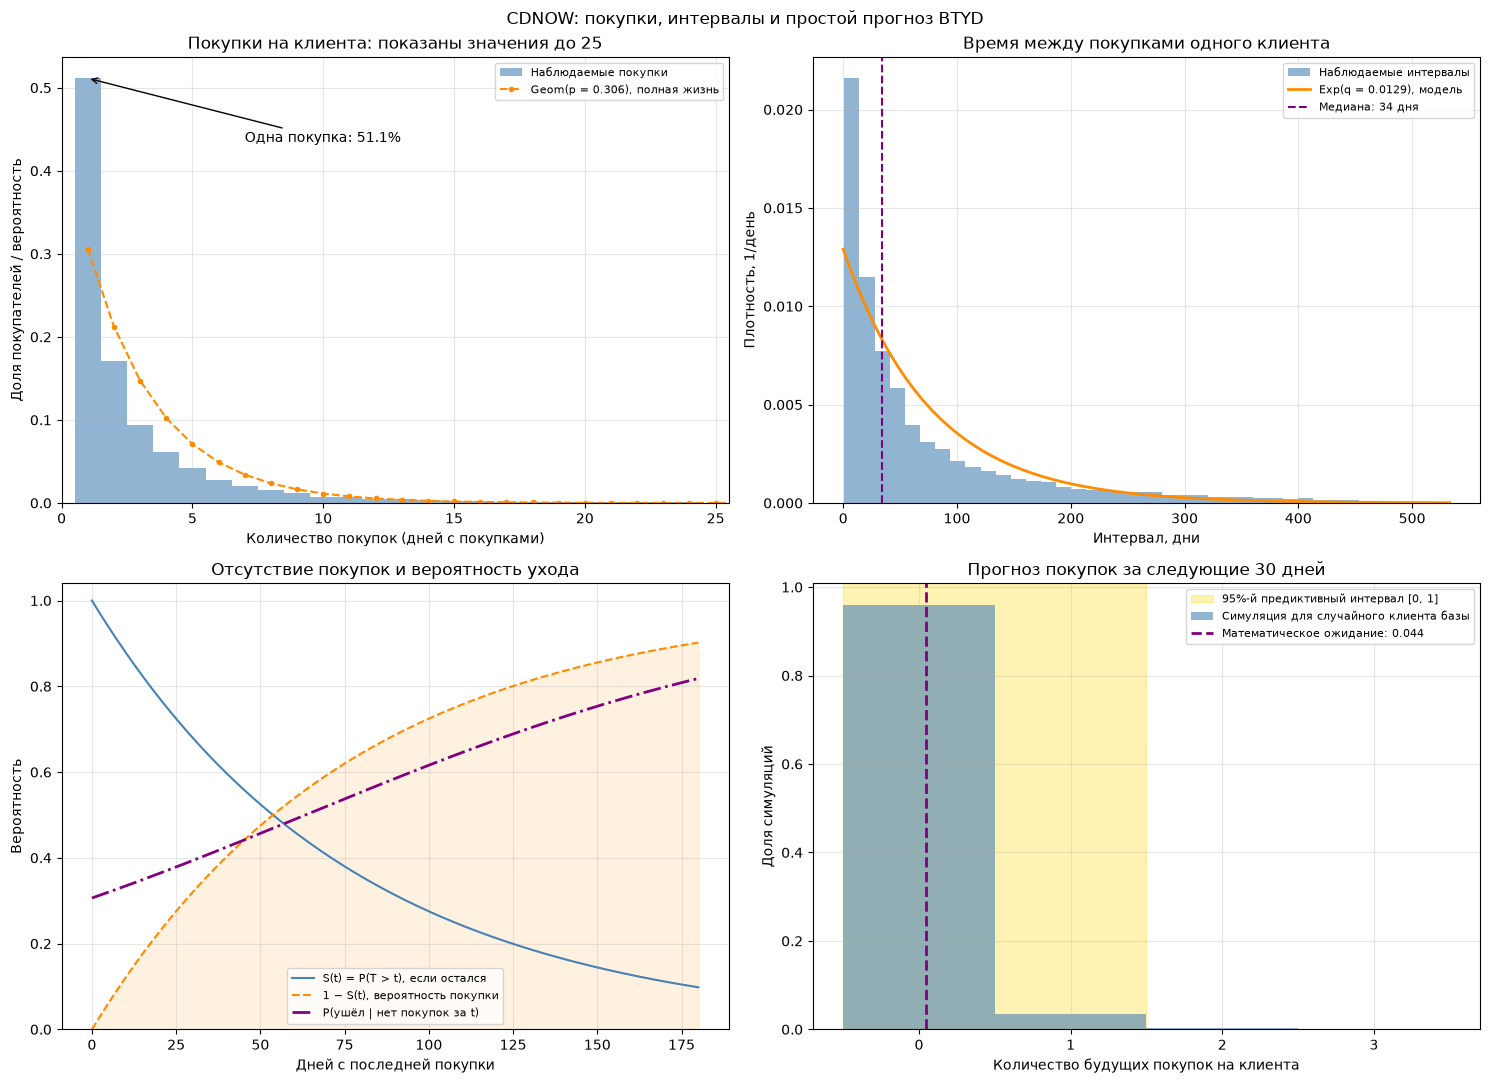

In [5]:
np.random.seed(42)
horizon = 30
n_simulations = 20000
selected_customers = np.random.randint(0, len(customer_stats), n_simulations)
prob_alive = customer_stats['prob_alive'].to_numpy()[selected_customers]
alive = np.random.random(n_simulations) < prob_alive
time = np.zeros(n_simulations)
forecast = np.zeros(n_simulations, dtype=int)

while alive.any():
    indices = np.flatnonzero(alive)
    time[indices] += np.random.exponential(scale=1 / q_est, size=len(indices))
    buying = indices[time[indices] <= horizon]
    alive[indices] = False
    forecast[buying] += 1
    alive[buying] = np.random.random(len(buying)) > p_est

expected_forecast = (customer_stats['prob_alive'].mean()
                     * (1 - np.exp(-p_est * q_est * horizon)) / p_est)
lower, upper = np.quantile(forecast, [0.025, 0.975])
print(f'Ожидаемые покупки на клиента за 30 дней: {expected_forecast:.3f}')
print(f'Среднее по симуляциям: {forecast.mean():.3f}')
print(f'95%-й предиктивный интервал: [{lower:.0f}, {upper:.0f}] покупок')
print(f'Доля прогнозов без покупок: {(forecast == 0).mean():.1%}')

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
ax = axes[0, 0]
counts = customer_stats['purchase_count']
max_quantity = int(counts.max())
ax.hist(counts, bins=range(1, max_quantity + 2), density=True, align='left',
        color='steelblue', alpha=0.6, label='Наблюдаемые покупки')
k = np.arange(1, max_quantity + 1)
ax.plot(k, stats.geom.pmf(k, p_est), 'o--', color='darkorange', markersize=3,
        label=f'Geom(p = {p_est:.3f}), полная жизнь')
ax.annotate(f'Одна покупка: {one_time_share:.1%}', xy=(1, one_time_share),
            xytext=(7, one_time_share * 0.85), arrowprops={'arrowstyle': '->', 'color': 'black'})
ax.set_xlim(0, 25.5)
ax.set_title('Покупки на клиента: показаны значения до 25')
ax.set_xlabel('Количество покупок (дней с покупками)')
ax.set_ylabel('Доля покупателей / вероятность')

ax = axes[0, 1]
x_days = np.linspace(0, gaps.max(), 500)
ax.hist(gaps, bins=40, density=True, color='steelblue', alpha=0.6, label='Наблюдаемые интервалы')
ax.plot(x_days, stats.expon.pdf(x_days, scale=1 / q_est), color='darkorange',
        linewidth=2, label=f'Exp(q = {q_est:.4f}), модель')
ax.axvline(gaps.median(), color='purple', linestyle='--', label=f'Медиана: {gaps.median():.0f} дня')
ax.set_title('Время между покупками одного клиента')
ax.set_xlabel('Интервал, дни')
ax.set_ylabel('Плотность, 1/день')

ax = axes[1, 0]
t = np.linspace(0, 180, 400)
survival = np.exp(-q_est * t)
prob_dead = p_est / (p_est + (1 - p_est) * survival)
ax.plot(t, survival, color='steelblue', label='S(t) = P(T > t), если остался')
ax.plot(t, 1 - survival, color='darkorange', linestyle='--', label='1 − S(t), вероятность покупки')
ax.fill_between(t, 1 - survival, color='darkorange', alpha=0.12)
ax.plot(t, prob_dead, color='purple', linestyle='-.', linewidth=2, label='P(ушёл | нет покупок за t)')
ax.set_title('Отсутствие покупок и вероятность ухода')
ax.set_xlabel('Дней с последней покупки')
ax.set_ylabel('Вероятность')
ax.set_ylim(0, 1.04)

ax = axes[1, 1]
ax.axvspan(lower - 0.5, upper + 0.5, color='gold', alpha=0.3,
           label=f'95%-й предиктивный интервал [{lower:.0f}, {upper:.0f}]')
ax.hist(forecast, bins=np.arange(-0.5, forecast.max() + 1.5), density=True,
        color='steelblue', alpha=0.6, label='Симуляция для случайного клиента базы')
ax.axvline(expected_forecast, color='purple', linestyle='--', linewidth=2,
           label=f'Математическое ожидание: {expected_forecast:.3f}')
ax.set_title('Прогноз покупок за следующие 30 дней')
ax.set_xlabel('Количество будущих покупок на клиента')
ax.set_ylabel('Доля симуляций')
ax.set_xticks(range(int(forecast.max()) + 1))
for ax in axes.flat:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
fig.suptitle('CDNOW: покупки, интервалы и простой прогноз BTYD')
plt.tight_layout()
plt.show()

**НАПИШИТЕ ВЫВОДЫ ПО ГРАФИКАМ, КОТОРЫЕ БЫ ВЫ СДЕЛАЛИ, КАК АНАЛИТИК (ОТВЕТЫ НА ВОПРОСЫ + РАССУЖДЕНИЯ)**

1. Одна покупка за период была у 51.1% клиентов. Это повод изучить повторные покупки,
но не доказательство ухода всех этих клиентов. Геометрическая кривая описывает всю жизнь клиента,
а данные ограничены периодом наблюдения. На графике показаны значения до 25, нормировка использует всех клиентов.

2. Медиана наблюдаемых интервалов — 34 дня. Есть длинный правый хвост: некоторые клиенты возвращаются через месяцы.
Экспоненциальная кривая не полностью описывает форму. Интервалы видны только у вернувшихся клиентов внутри периода;
по ним нельзя установить срок ухода всех пользователей.

3. Чем дольше нет покупок, тем выше модельная вероятность ухода. Отсутствие покупки и уход — разные события.
Модель с общими p и q не учитывает, что клиенты имеют разную частоту покупок и склонность к уходу.

4. Для случайного клиента базы на конец июня 1998 ожидается 0.044 покупки за следующие 30 дней.
В 96.0% симуляций покупок нет, центральный 95%-й предиктивный интервал — от 0 до 1 покупки.
Новые клиенты не учитываются. Это приближение; перед применением нужно проверить прогноз на отложенном периоде
и сравнить с полной BG/NBD.

Использована простая BTYD с общими p и q. Оценка учитывает последний период без покупок:
$$L_i=[(1-p)q]^r e^{-qt_x}[p+(1-p)e^{-q(T-t_x)}],$$
где r — число повторных покупок, t_x — время от первой до последней покупки, T — длительность наблюдения.
Покупки за один день объединены, потому что даты известны только до дня.

При $S(t)=e^{-qt}$ величина $1-S(t)$ — вероятность покупки у оставшегося клиента,
а не вероятность ухода. Поэтому вероятность ухода показана отдельной кривой по формуле из теоретической части.
Заливка в прогнозе — предиктивный интервал числа покупок, без учёта неопределённости p и q.


# Бонус с собеса (2+ pt)

Мне понравилась задачка с собеседования, поэтому показываю ее вам:

> На маркетплейсе есть $n$ категорий товаров, в каждой из которых есть $n_i$ различных позиций товаров. Пользователь собирает корзину, делая покупки из любых категорий (может взять из категории, может не взять, может взять из нескольких). Известно, что **средний чек по каждой из категорий** вырос за последний месяц. Что могло произойти с **общим средним чеком**?

Сначала поймите, как считается общий чек. В рассуждениях вы свободны, главное оформите так, чтобы я могла _**понять, где ваш ответ и выводы, на чем они основаны**_. Вы можете делать теоретические выкладки, симуляции и визуализацию. Ничего из этого не запрещено.

In [6]:
# Общий средний чек = суммарная выручка / число корзин.
# Он может вырасти, снизиться или остаться прежним: меняется состав корзин.
# Если a_i — чек категории, N_i — корзины с ней, N — все корзины,
# общий чек равен sum(a_i * N_i / N). Веса N_i / N могут меняться.
# В корзине с несколькими категориями сумма весов может быть больше 1.
# Ниже пример: 100 корзин, в каждой только одна категория.
# Чеки обеих категорий растут, а общий чек становится 610, 120 или остаётся 190.

example = pd.DataFrame({
    'Сценарий': ['Прошлый месяц', 'Общий чек вырос', 'Общий чек снизился', 'Общий чек не изменился'],
    'Чек категории A': [100, 110, 110, 110],
    'Чек категории B': [1000, 1110, 1110, 1110],
    'Корзин A': [90, 50, 99, 92],
    'Корзин B': [10, 50, 1, 8]
})
example['Выручка'] = (example['Чек категории A'] * example['Корзин A']
                      + example['Чек категории B'] * example['Корзин B'])
example['Общий средний чек'] = example['Выручка'] / (example['Корзин A'] + example['Корзин B'])
display(example)

,Сценарий,Чек категории A,Чек категории B,Корзин A,Корзин B,Выручка,Общий средний чек
0,Прошлый месяц,100,1000,90,10,19000,190.0
1,Общий чек вырос,110,1110,50,50,61000,610.0
2,Общий чек снизился,110,1110,99,1,12000,120.0
3,Общий чек не изменился,110,1110,92,8,19000,190.0
